In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [2]:
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [3]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/praveen/save_3_classes_data',
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)

Found 954 files belonging to 3 classes.


In [4]:
class_names = dataset.class_names
class_names

['AK', 'BCC', 'SK']

In [5]:
def flatten_dataset(dataset):
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')
            img_flattened = img_array.flatten()
            flat_data.append(img_flattened)
            target_data.append(label.numpy())
    return np.array(flat_data), np.array(target_data)

In [34]:
train_size = int(0.85 * len(dataset))
test_size = int(0.15 * len(dataset))

In [35]:
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size).take(test_size)

In [36]:
x_train, y_train = flatten_dataset(train_ds)
x_test, y_test = flatten_dataset(test_ds)

In [37]:
rf = RandomForestClassifier(random_state=90)
rf.fit(x_train, y_train)

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='auto',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=90, verbose=0,
                       warm_start=False)

In [38]:
y_pred1 = rf.predict(x_test)
accuracy1 = accuracy_score(y_pred1, y_test)
print("The model is {:.2f}% accurate".format(accuracy1 * 100))

The model is 92.19% accurate


In [39]:
report = classification_report(y_test, y_pred1, target_names=class_names)
print("Classification Report:\n\n", report)

Classification Report:

               precision    recall  f1-score   support

          AK       0.90      0.93      0.92        41
         BCC       0.91      0.89      0.90        46
          SK       0.95      0.95      0.95        41

    accuracy                           0.92       128
   macro avg       0.92      0.92      0.92       128
weighted avg       0.92      0.92      0.92       128



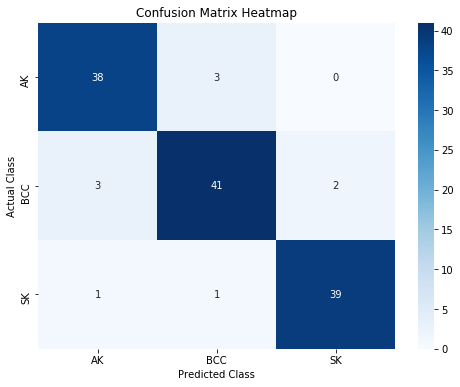

In [40]:
cm = confusion_matrix(y_test, y_pred1)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()